In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import math
import h5py
import yaml
import os
import os.path as _ospath
import tkinter as tk
import tkinter.filedialog

%matplotlib inline

# ------------------------------------------------------------------
# EDIT THESE
# ------------------------------------------------------------------
half_width   = 12    # +/- window around each reference
pixel_size   = 97   # nm per camera pixel
oversampling = 21   # render bins per camera pixel
output_dir   = r"\\bigdata1\dataschnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn"
base_name    = "Stretchin_blockAverage_Mutant_Zdisc"
# ------------------------------------------------------------------


def to_unc(path):
    """Convert a POSIX-style path from Excel (/bigdata1/a/b) to a Windows UNC path (\\\\bigdata1\\a\\b).
    Drive-letter paths and existing UNC paths are left untouched."""
    if not isinstance(path, str):
        return path
    p = path.strip().strip('"\'')
    if not p or p.startswith("\\\\") or (len(p) > 1 and p[1] == ":"):
        return p
    return "\\\\" + p.replace("/", "\\").lstrip("\\")


def pick_excel_file():
    """Open a file dialog that is forced to the front."""
    root = tk.Tk()
    root.withdraw()
    root.attributes("-topmost", True)
    root.update()
    root.lift()
    root.focus_force()
    path = tkinter.filedialog.askopenfilename(
        parent=root,
        title="Select reference excel file",
        filetypes=[("Excel files", "*.xlsx *.xls")],
    )
    root.destroy()
    return path


# ---- pick the excel file with file paths + references ----
excel_path = pick_excel_file()
if not excel_path:
    raise ValueError("No excel file selected.")
print(f"Selected: {excel_path}")

# ---- read file paths + references from excel ----
refs_df = pd.read_excel(excel_path)

file_refs = {}   # UNC path (used to open files) -> list of references
posix_of  = {}   # UNC path -> original POSIX path from Excel (used as label in output)
missing   = []

for _, row in refs_df.iterrows():
    if pd.isna(row["file_path"]):
        continue

    refs = row["references"]
    if isinstance(refs, str):
        refs = ast.literal_eval(refs)
    elif isinstance(refs, (int, float, np.number)):
        refs = [] if pd.isna(refs) else [refs]

    original = str(row["file_path"]).strip().strip('"\'')
    path = to_unc(original)

    posix_of[path] = original
    file_refs[path] = refs
    if not os.path.exists(path):
        missing.append(path)

print(f"Loaded {len(file_refs)} files with references")
if missing:
    print(f"WARNING: {len(missing)} path(s) not found, e.g.:\n  {missing[0]}")
file_refs

Selected: //bigdata1/dataschnorrer/EqpSchnorrer/Aditya/Experiments/Proj RNAi/Mutant/Strn/ChangePoint_Detection__ProjRNAi_Mutant_Strn/ProjRNAi_Mutant_Zdisc_blockAverages.xlsx
Loaded 13 files with references


{'\\\\bigdata1\\dataSchnorrer\\EqpSchnorrer\\Aditya\\Experiments\\Proj RNAi\\Mutant\\Strn\\ChangePoint_Detection__ProjRNAi_Mutant_Strn\\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#3.hdf5': [54.199],
 '\\\\bigdata1\\dataSchnorrer\\EqpSchnorrer\\Aditya\\Experiments\\Proj RNAi\\Mutant\\Strn\\ChangePoint_Detection__ProjRNAi_Mutant_Strn\\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#4.hdf5': [28.995,
  57.391],
 '\\\\bigdata1\\dataSchnorrer\\EqpSchnorrer\\Aditya\\Experiments\\Proj RNAi\\Mutant\\Strn\\ChangePoint_Detection__ProjRNAi_Mutant_Strn\\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#5.hdf5': [25.394,
  50.988],
 '\\\\bigdata1\\dataSchnorrer\\EqpSchnorrer\\Aditya\\Experiments\\Proj RNAi\\Mutant\\Strn\\ChangePoint_Detection__ProjRNAi_Mutant_Strn\\20260609_sample3

In [47]:
all_pieces = []
for loc_filename, ref_x_list in file_refs.items():
    print(f"Processing {loc_filename} with references {ref_x_list}")
    df = pd.read_hdf(loc_filename, key="locs")      # UNC path, opens fine on Windows

    for ref in ref_x_list:
        mask = (df["x"] >= ref - half_width) & (df["x"] <= ref + half_width)
        subset = df.loc[mask].copy()

        if len(subset) == 0:
            print(f"  [warning] no localizations found within +/-{half_width} of x={ref}")
            continue

        subset["x_rel"] = subset["x"] - ref
        subset["y_rel"] = subset["y"] - subset["y"].mean()
        subset["ref_x"] = ref
        subset["source_file"] = posix_of.get(loc_filename, loc_filename)   # POSIX label for output
        all_pieces.append(subset)

rel_all = pd.concat(all_pieces, ignore_index=True)
print(f"Total aligned localizations across all files: {len(rel_all)}")
rel_all.head()

Processing \\bigdata1\dataSchnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#3.hdf5 with references [54.199]
Processing \\bigdata1\dataSchnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#4.hdf5 with references [28.995, 57.391]
Processing \\bigdata1\dataSchnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\20260609_sample3_1_ProjRNAi_Mutant_Strn_P3_Cy3B_2nM_Phall488_XmW_picasso_20230418_3_filter_withZ_render_picked_DBSCAN_3_#5.hdf5 with references [25.394, 50.988]
Processing \\bigdata1\dataSchnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_M

,index,frame,x,y,z,photons,sx,sy,sz,bg,lpx,lpy,lpz,ellipticity,net_gradient,prob,x_rel,y_rel,ref_x,source_file
0,100.0,0,47.497139,6.222056,235.341797,4481.233398,0.081451,0.097342,55.556610,808.605713,0.081451,0.097342,55.556610,0.081451,0.081451,1.0,-6.701862,1.800920,54.199,/bigdata1/dataSchnorrer/EqpSchnorrer/Aditya/Ex...
1,591.0,1,47.435368,6.200541,162.021194,4226.388184,0.072858,0.086450,66.530266,785.281677,0.072858,0.086450,66.530266,0.072858,0.072858,1.0,-6.763634,1.779406,54.199,/bigdata1/dataSchnorrer/EqpSchnorrer/Aditya/Ex...
2,984.0,2,47.491165,6.193938,130.166290,4328.427246,0.068100,0.078051,61.493446,860.877258,0.068100,0.078051,61.493446,0.068100,0.068100,1.0,-6.707836,1.772802,54.199,/bigdata1/dataSchnorrer/EqpSchnorrer/Aditya/Ex...
3,1363.0,3,47.531853,6.150190,172.642105,4814.214355,0.104203,0.116334,81.076576,846.547791,0.104203,0.116334,81.076576,0.104203,0.104203,1.0,-6.667149,1.729055,54.199,/bigdata1/dataSchnorrer/EqpSchnorrer/Aditya/Ex...
4,1721.0,4,47.565510,6.155794,151.337265,3830.241943,0.111682,0.124208,94.498688,907.005432,0.111682,0.124208,94.498688,0.111682,0.111682,1.0,-6.633492,1.734658,54.199,/bigdata1/dataSchnorrer/EqpSchnorrer/Aditya/Ex...


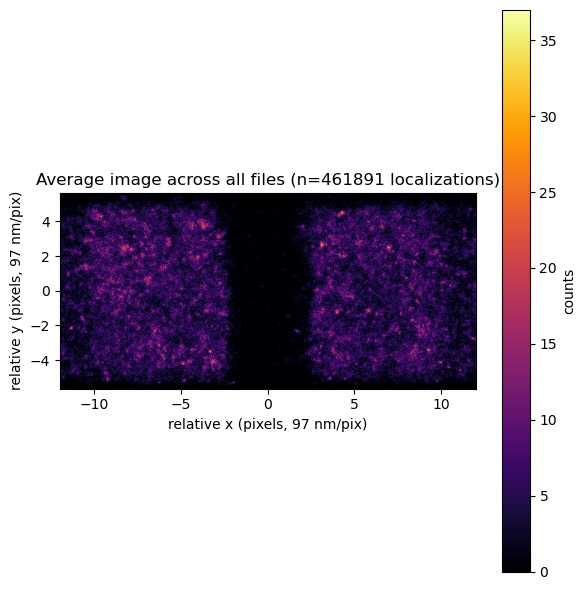

In [48]:
x = rel_all["x_rel"].values
y = rel_all["y_rel"].values

bin_size = 1.0 / oversampling
x_bins = np.arange(-half_width, half_width + bin_size, bin_size)
y_half = np.max(np.abs(y)) if len(y) else half_width
y_bins = np.arange(-y_half, y_half + bin_size, bin_size)

H, xedges, yedges = np.histogram2d(x, y, bins=[x_bins, y_bins])

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(
    H.T,
    origin="lower",
    extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
    cmap="inferno",
    aspect="equal",
)
ax.set_xlabel(f"relative x (pixels, {pixel_size} nm/pix)")
ax.set_ylabel(f"relative y (pixels, {pixel_size} nm/pix)")
ax.set_title(f"Average image across all files (n={len(x)} localizations)")
fig.colorbar(im, ax=ax, label="counts")
plt.tight_layout()
plt.show()

In [49]:
original_cols = ["index", "frame", "x", "y", "z", "photons", "sx", "sy", "sz",
                  "bg", "lpx", "lpy", "lpz", "ellipticity", "net_gradient", "prob"]
original_cols = [c for c in original_cols if c in rel_all.columns]


def save_locs_hdf5(df, hdf5_path, yaml_path, x_col="x", y_col="y"):
    out = df.copy()
    out["frame"] = pd.to_numeric(out["frame"], downcast="integer", errors="coerce")

    for col in out.columns:
        if out[col].dtype == object:
            out[col] = out[col].astype(str).values.astype("S")

    hw = np.max(np.array([math.ceil(out[x_col].max()), math.ceil(out[y_col].max())]))
    height = hw
    width = hw
    frames = int(np.max(out["frame"]) + 1)
    dict_file = {"Frames": frames, "Height": height, "Width": width}

    locs = out.to_records(index=False)
    with h5py.File(hdf5_path, "w") as locs_file:
        locs_file.create_dataset("locs", data=locs)

    with open(yaml_path, "w") as f:
        yaml.dump(dict_file, f)

    print(f"Saved {len(out)} localizations to:\n  {hdf5_path}\n  {yaml_path}")


# ---- FILE 1: original x/y untouched, plus x_rel/y_rel/ref_x/source_file added ----
traceable = rel_all[original_cols].copy()
traceable["x_rel"] = rel_all["x_rel"]
traceable["y_rel"] = rel_all["y_rel"]
traceable["ref_x"] = rel_all["ref_x"]
traceable["source_file"] = rel_all["source_file"]

file1_hdf5_path = _ospath.join(output_dir, f"{base_name}.hdf5")
file1_yaml_path = _ospath.join(output_dir, f"{base_name}.yaml")
save_locs_hdf5(traceable, file1_hdf5_path, file1_yaml_path)


# ---- FILE 2: exactly the original column layout, x/y REPLACED with aligned+shifted values ----
adjusted = rel_all[original_cols].copy()
adjusted["x"] = rel_all["x_rel"]
adjusted["y"] = rel_all["y_rel"]

x_shift = adjusted["x"].min()
y_shift = adjusted["y"].min()
adjusted["x"] = adjusted["x"] - x_shift
adjusted["y"] = adjusted["y"] - y_shift

file2_hdf5_path = _ospath.join(output_dir, f"{base_name}_adjusted for picasso.hdf5")
file2_yaml_path = _ospath.join(output_dir, f"{base_name}_adjusted for picasso.yaml")
save_locs_hdf5(adjusted, file2_hdf5_path, file2_yaml_path)

print(f"\nx shifted by {-x_shift:.3f}, y shifted by {-y_shift:.3f} for the adjusted file")

Saved 461891 localizations to:
  \\bigdata1\dataschnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\Stretchin_blockAverage_Mutant_Zdisc.hdf5
  \\bigdata1\dataschnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\Stretchin_blockAverage_Mutant_Zdisc.yaml
Saved 461891 localizations to:
  \\bigdata1\dataschnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\Stretchin_blockAverage_Mutant_Zdisc_adjusted for picasso.hdf5
  \\bigdata1\dataschnorrer\EqpSchnorrer\Aditya\Experiments\Proj RNAi\Mutant\Strn\ChangePoint_Detection__ProjRNAi_Mutant_Strn\Stretchin_blockAverage_Mutant_Zdisc_adjusted for picasso.yaml

x shifted by 12.000, y shifted by 5.643 for the adjusted file
